# Lab 4 Task 2: OFDM Phase Offset

Complete the OFDM accounting and pilot phase calculation, then measure BER and FER from 0 through 90 degrees.


In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab4_tools.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 4 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB4_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)
print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab4/work/captures


## OFDM calculations


In [2]:
nfft = 64
cyclic_prefix_samples = 16
pilot_subcarriers = 4
qpsk_bits_per_symbol = 2

# Derive the active-carrier and frame counts.
active_subcarriers = 52
data_subcarriers = active_subcarriers - pilot_subcarriers
bits_per_frame = data_subcarriers * qpsk_bits_per_symbol
time_samples_per_frame = nfft + cyclic_prefix_samples

print("data subcarriers:", data_subcarriers)
print("bits per frame:", bits_per_frame)
print("time samples per frame:", time_samples_per_frame)

data subcarriers: 48
bits per frame: 96
time samples per frame: 80


In [4]:
assert data_subcarriers == 48
assert bits_per_frame == 96
assert time_samples_per_frame == 80
print("OFDM accounting passed.")

OFDM accounting passed.


## Pilot phase correction check


In [5]:
known_pilots = np.ones(4, dtype=complex)
received_pilots = known_pilots * np.exp(1j * np.deg2rad(30))

# Estimate and remove the common pilot phase.
phase_hat_rad = np.angle(np.sum(np.conj(known_pilots) * received_pilots))
corrected_pilots = received_pilots * np.exp(-1j * phase_hat_rad)

print("estimated phase (degrees):", np.rad2deg(phase_hat_rad))
print("largest corrected pilot error:", np.max(np.abs(corrected_pilots - known_pilots)))

estimated phase (degrees): 29.999999999999996
largest corrected pilot error: 7.437084071668725e-18


In [6]:
assert np.isclose(np.rad2deg(phase_hat_rad), 30.0)
assert np.max(np.abs(corrected_pilots - known_pilots)) < 1e-12
print("Pilot correction passed.")


Pilot correction passed.


## Full phase sweep


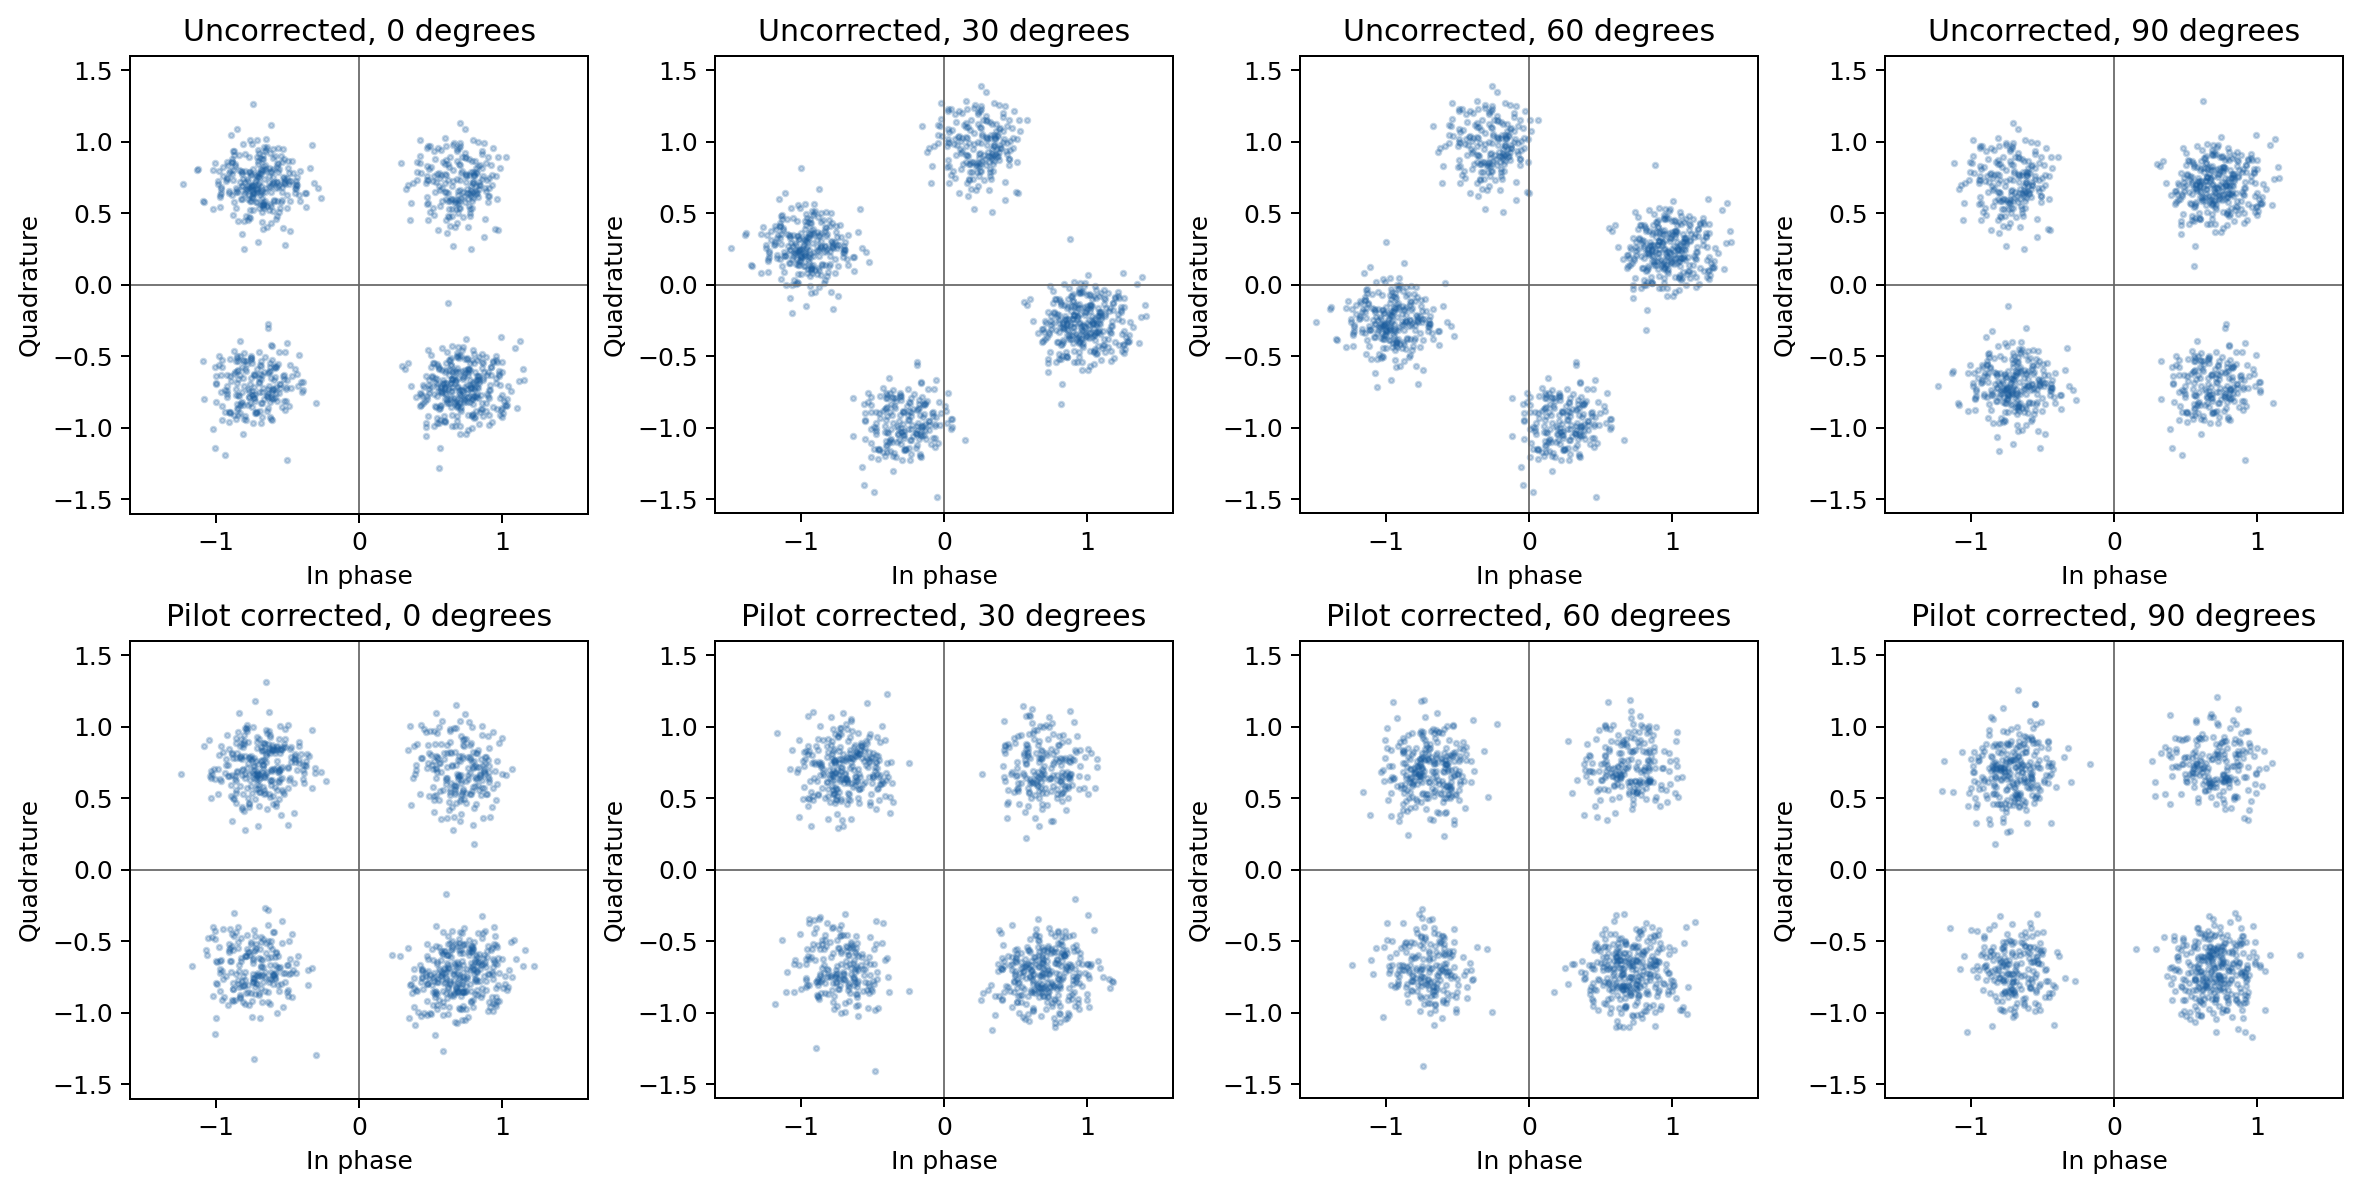

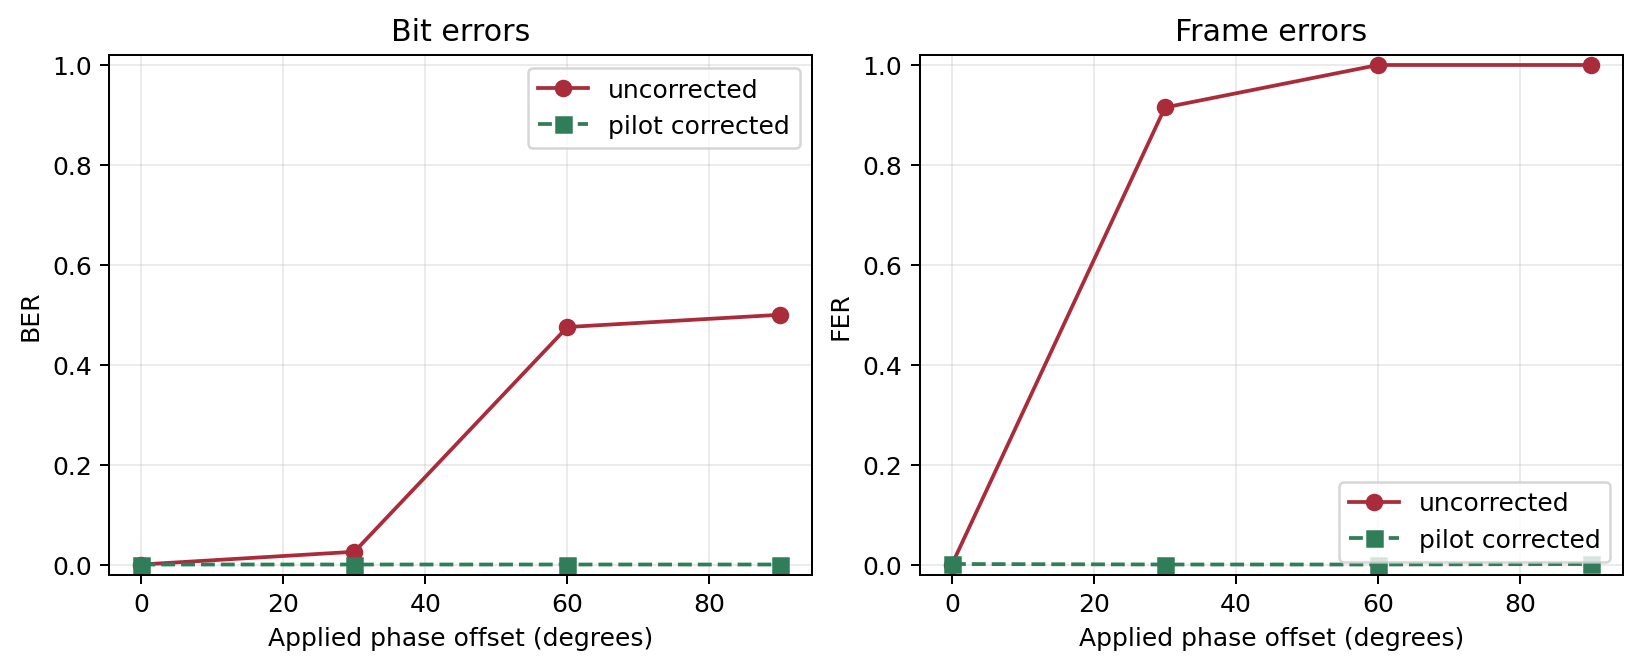

In [11]:
from lab4_tools import ofdm_reference, plot_ofdm_phase_study

result = ofdm_reference(
    phase_degrees=(0, 30, 60, 90),
    frames=1000,
    ebn0_db=10.0,
    message="hello world",
)
figure_paths = plot_ofdm_phase_study(result, FIGURE_DIR)
for path in figure_paths:
    display(Image(filename=path))

<span style="color:#165696"><b>Report.</b> Report BER and FER before correction at all four phase offsets. Report the mean pilot phase estimate and corrected error rates BER and FER. Include both saved figures and the result table. </span>

In [14]:
phase_results_df = pd.DataFrame([{
    "Phase Offset (deg)": row["phase_degrees"], "BER": row["ber"], "FER": row["fer"],
    "Mean Pilot Estimated Phase  (deg)": row["estimated_phase_mean_degrees"],
    "Corrected BER": row["corrected_ber"], "Corrected FER": row["corrected_fer"],
} for row in result["rows"] ])

display( phase_results_df.style.format({"BER": "{:.6f}", "FER": "{:.3f}", "Mean Pilot Estimated Phase (deg)": "{:.3f}",
                                        "Corrected BER": "{:.7f}", "Corrected FER": "{:.3f}"}))

,Phase Offset (deg),BER,FER,Mean Pilot Estimated Phase (deg),Corrected BER,Corrected FER
0,0,0.000000,0.000,0.156070,0.0000104,0.001
1,30,0.025531,0.915,30.162642,0.0000000,0.000
2,60,0.475469,1.000,60.118485,0.0000000,0.000
3,90,0.500000,1.000,90.050035,0.0000104,0.001


<span style="color:#165696"><b>Report.</b> Explain why FER may approach one while BER remains much smaller. </span>

FER can approach one even when BER is much smaller because a frame is counted as incorrect if it contains even one bit error. Each frame contains 96 bits, so even a relatively small BER can make it likely that at least one of those 96 bits is wrong. For example, at 30° phase offset, the BER is only 0.0255, but the FER is already 0.915, meaning 91.5% of frames contain at least one error. At 60° and 90°, the BER rises to about 0.475 and 0.500, respectively, causing the FER to reach 1.0, so every frame contains at least one error.

<span style="color:#165696"><b>Report.</b> Explain the difference between constant phase offset and CFO. Explain why a constant phase rotates every subcarrier similarly, while CFO
produces phase that changes with sample or OFDM-symbol index. </span>

A constant phase offset applies the same fixed rotation to the entire received OFDM symbol, so all subcarriers are rotated by approximately the same angle. In contrast, carrier frequency offset (CFO) causes phase to continuously accumulate with time, so the phase changes with the sample index and from one OFDM symbol to the next. Mathematically, constant phase behaves like $e^{j\phi}$, while CFO behaves like $e^{j2\pi\Delta f n/f_s}$, which depends on sample index n. Therefore, a constant phase can be corrected with one common rotation, while CFO produces a time-varying phase error that must first be estimated and compensated.

<span style="color:#165696"><b>Report.</b> Include the OFDM grid, IFFT and FFT code. </span>

The OFDM grid, IFFT, and FFT code are all included in the function `ofdm_phase_sweep()` in Will's support file `support/lab4_dsp.py`. The OFDM grid is output below.

In [4]:
from lab4_tools import get_ofdm_grid
result = get_ofdm_grid(
    phase_degrees=(0, 30, 60, 90),
    frames=1000,
    ebn0_db=10.0,
    message="hello world",
)
df2 = pd.DataFrame(result)
display(df2)

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
1,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
2,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
3,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
4,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
996,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
997,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
998,0.0+0.0j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107-0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,...,0.707107+0.707107j,0.707107-0.707107j,-0.707107+0.707107j,1.0+0.0j,-0.707107-0.707107j,-0.707107-0.707107j,0.707107+0.707107j,-0.707107+0.707107j,0.707107+0.707107j,0.707107+0.707107j
